In [32]:
import utide
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pinner2026_jpo_code
import pinner2026_jpo_code.constants
import pinner2026_jpo_code.spectra

In [2]:
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"
DERIVED_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "derived"

In [4]:
velocity = pd.read_csv(INTERIM_DATA_DIR / "velo_at_C.csv")
velocity = velocity.set_index(pd.to_datetime(velocity["time_2350"]).dt.round("min"))
velocity = velocity.drop("time_2350", axis="columns")
velocity["2350"] = velocity["2350"].apply(lambda x: complex(x))

In [5]:
velocity.head()

,2350
time_2350,
2017-01-26 11:50:00,-0.0086+0.0537j
2017-01-26 13:50:00,-0.0475+0.0206j
2017-01-26 15:50:00,-0.0440-0.0151j
2017-01-26 17:50:00,-0.0473-0.0209j
2017-01-26 19:50:00,0.0045+0.0436j


In [51]:
CONSTITUENTS = pinner2026_jpo_code.constants.get_tidal_frequencies_in_hours(tide_type="padman")
constit = [constituent.upper() for constituent in CONSTITUENTS.keys()]
constit.extend(["M3", "M4", "S4"])
print(constit)

['M2', 'S2', 'N2', 'K2', 'K1', 'O1', 'P1', 'Q1', 'MF', 'MM', 'M3', 'M4', 'S4']


In [52]:
coef = utide.solve(
    t=velocity.index,
    u=np.real(velocity["2350"].to_numpy()),
    v=np.imag(velocity["2350"].to_numpy()),
    lat=-70.67,
    # constit="auto",
    constit=constit,
    method="robust",
    conf_int="MC",
    verbose=True,
)

solve: matrix prep ... solution ... done.


The amplitudes and phases from the fit are now in the `coef` data structure (a Bunch), which can be used directly in the `reconstruct` function to generate a hindcast or forecast of the tides at the times specified in the `time` array.

In [53]:
print(coef.keys())

dict_keys(['name', 'aux', 'nR', 'nNR', 'nI', 'rf', 'weights', 'Lsmaj', 'Lsmin', 'theta', 'g', 'umean', 'vmean', 'uslope', 'vslope', 'g_ci', 'Lsmaj_ci', 'Lsmin_ci', 'theta_ci', 'diagn', 'PE', 'SNR'])


In [54]:
tide = utide.reconstruct(velocity.index, coef, verbose=True)

prep/calcs ... done.


The output from the reconstruction is also a Bunch:

In [55]:
print(tide.keys())

dict_keys(['t_in', 'epoch', 'constit', 'min_SNR', 'min_PE', 't_mpl', 'u', 'v'])


In [56]:
t = velocity.index.to_pydatetime()
v = np.imag(velocity["2350"].to_numpy())
residual = velocity["2350"] - (tide.u + 1j * tide.v)

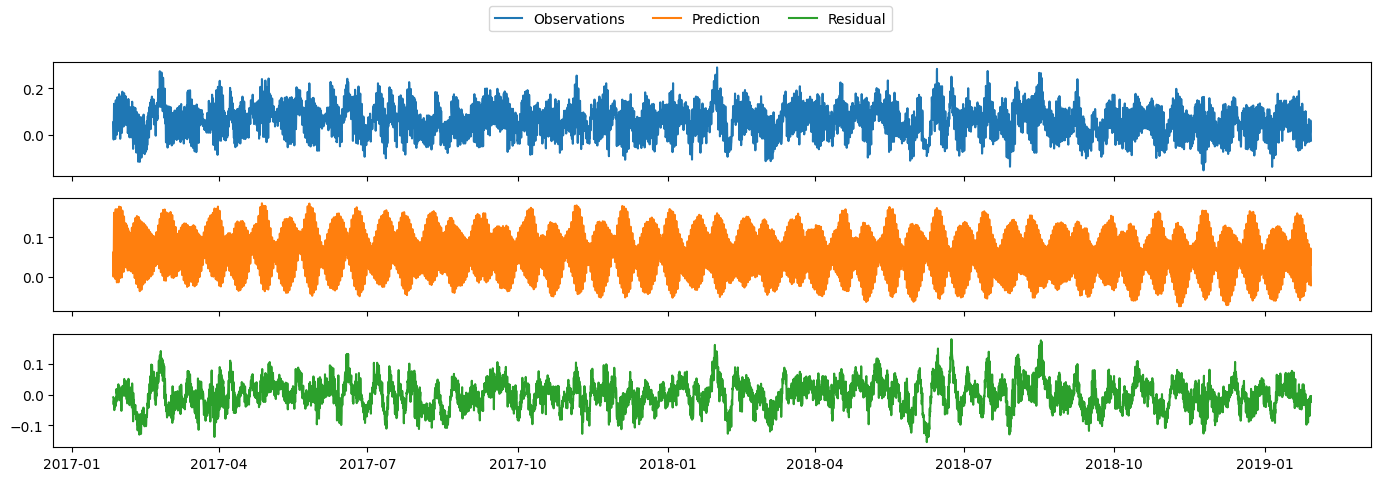

In [57]:
fig, (ax0, ax1, ax2) = plt.subplots(figsize=(17, 5), nrows=3, sharex=True)

ax0.plot(t, v, label="Observations", color="C0")
ax1.plot(t, tide.v, label="Prediction", color="C1")
ax2.plot(t, np.imag(residual.to_numpy()), label="Residual", color="C2")
fig.legend(ncol=3, loc="upper center");

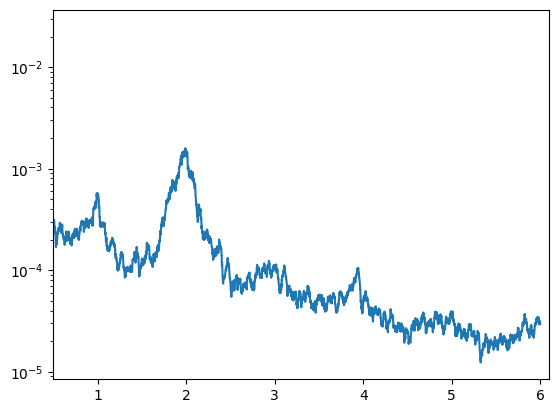

In [61]:
freq, PSD = pinner2026_jpo_code.spectra.total_multitaper(residual.to_numpy(), dt=1 / 12, P=12)
fig, ax = plt.subplots(1)
ax.set_xlim(0.5, 6.1)
ax.semilogy(freq, PSD)

In [66]:
try:
    coef = utide.solve(
        t=residual.index,
        u=np.real(residual.to_numpy()),
        v=np.imag(residual.to_numpy()),
        lat=-70.67,
        # constit="auto",
        method="robust",
        conf_int="MC",
        verbose=True,
    )
except np.linalg.LinAlgError as e:
    print(e)

solve: matrix prep ... solution ... SVD did not converge
